In [ ]:
#print(np.__version__)
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.preprocessing import minmax_scale
from scipy.stats import multivariate_normal
import numpyro.distributions as dist
import os
import arviz as az
import matplotlib.pyplot as plt
import pickle
import json
import jax.numpy as jnp
import ast  
import re
import glob
import seaborn as sns

In [2]:
print(os.getcwd())

/Users/verra/Documents/AVGEN_pub/gen-avo/behavioral-modeling/GP


This script extracts parameters of fitted GPs for PRE and POST ratings, then saves them to .csv file

The different models assessed are combinations of distance [EUC/MANH] x kernel [RBF/LIN]

### Pre ratings

In [3]:
parent_dir = os.path.abspath(os.path.join(os.getcwd(), "../../.."))
directory = os.path.join(parent_dir, "fitted/gp_fitted/ratingPRE")

csv_files = glob.glob(os.path.join(directory, "*.csv"))
good_files = []
bad_files = []

for f in csv_files:
    try:
        df_temp = pd.read_csv(f)
        good_files.append(f)
    except pd.errors.EmptyDataError:
        bad_files.append(f)
    except Exception as e:
        print(f"Problem with {f}: {e}")
        bad_files.append(f)

if good_files:
    df = pd.concat((pd.read_csv(f) for f in good_files), ignore_index=True)
    print(f"\nLoaded {len(good_files)} of {len(csv_files)} files successfully.")
    print(f"Skipped {len(bad_files)} bad/empty files.")
    print(f"Total rows: {len(df)}")
    print(f"Models: {df['model'].unique()}")
    print(f"Unique IDs: {len(df['ID'].unique())}")



Loaded 15943 of 15943 files successfully.
Skipped 0 bad/empty files.
Total rows: 109359
Models: ['euc_rbf' 'euc_rbf_peak' 'manh_lin' 'euc_lin' 'manh_lin_peak' 'manh_rbf'
 'manh_rbf_peak' 'euc_lin_peak']
Unique IDs: 237


In [4]:
#extract predictions for MDP here
mdpdf = df[df["Unnamed: 0"] == "res"].copy()
mdpdf = mdpdf[mdpdf["model"] == "euc_rbf_peak"]
mdpdf = mdpdf[["ID", "run", "mean"]].rename(columns={"mean": "rewards", "ID": "participant"})

# Clean up
def clean_mu(val, shape=(11,11)):
    if isinstance(val, str):

        cleaned = re.sub(r"[\[\]\n]", " ", val)
        cleaned = re.sub(r"\s+", " ", cleaned).strip()
        
        arr = np.fromstring(cleaned, sep=" ")
        arr = arr.reshape(shape) # Reshape into (11,11)

        rows = ["[" + " ".join(f"{x:g}" for x in row) + "]" for row in arr]
        arr_str = "[" + "\n ".join(rows) + "]"
        
        return arr_str
    return val

mdpdf["rewards"] = mdpdf["rewards"].apply(clean_mu)

print(mdpdf)

#mdpdf.to_csv("../MDP/fitted_mu.csv", index=False)

            participant  run  \
13      678123634315024    7   
27      826342134659933    2   
98      107195730980466    6   
116     515288423338733    1   
134     240909797496038    8   
...                 ...  ...   
108932  621775821369945    7   
109152  735848041903458    3   
109321  471454267567960    3   
109330   66250883594477    1   
109348  920878117433608    4   

                                                  rewards  
13      [[0.395384 0.619332 0.810742 0.886896 0.810742...  
27      [[13.7994 21.5702 28.2009 30.8367 28.2009 21.5...  
98      [[2.87703 6.95508 13.8215 22.5757 30.3047 33.4...  
116     [[22.3774 29.8631 37.3783 43.8792 48.3109 49.8...  
134     [[33.0201 38.139 41.584 42.8001 41.584 38.139 ...  
...                                                   ...  
108932  [[4.68716e-16 1.42811e-14 1.11154e-13 2.20356e...  
109152  [[8.06847 9.78131 10.979 11.41 10.979 9.78131 ...  
109321  [[23.9471 31.462 38.9037 45.2747 49.5881 51.11...  
109330  [[44.81

In [6]:
#some wrangling
def transform_res_rows(df, reshape_size=None):

    res_mask = df['Unnamed: 0'] == 'res'
    def parse_cell(cell):
        if isinstance(cell, str):

            numbers = re.findall(r"[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?", cell)
            arr = np.array([float(x) for x in numbers])
        else:
            arr = np.array(cell).flatten()
        return arr

    # Apply to all columns for 'res' rows
    numeric_cols = df.columns.difference(['ID','run','model'])
    df.loc[res_mask, numeric_cols] = df.loc[res_mask, numeric_cols].applymap(parse_cell)
    return df

df = transform_res_rows(df, reshape_size=(11, 11)) 
#print(df.head())


df['Unnamed: 0'] = df['Unnamed: 0'].apply(lambda x: str(x) if isinstance(x, np.ndarray) else x)
res_rows = df[df['Unnamed: 0'] == "[]"]
res_rows['mean_array'] = res_rows['mean'].apply(lambda x: np.array(x))
print(res_rows.head())
print(res_rows)

/var/folders/3q/315fpymx2zdc6gr50f3yzz6w0000gq/T/ipykernel_50346/3015307105.py:16: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df.loc[res_mask, numeric_cols] = df.loc[res_mask, numeric_cols].applymap(parse_cell)
/var/folders/3q/315fpymx2zdc6gr50f3yzz6w0000gq/T/ipykernel_50346/3015307105.py:16: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[array([-782.80482769]) array([-329.64930248]) array([-977.96839142]) ...
 array([-191.24986267]) array([-4725.64883423]) array([-345.06742287])]' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.loc[res_mask, numeric_cols] = df.loc[res_mask, numeric_cols].applymap(parse_cell)
/var/folders/3q/315fpymx2zdc6gr50f3yzz6w0000gq/T/ipykernel_50346/3015307105.py:16: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[

   Unnamed: 0                                               mean  \
4          []  [1.0189526, 1.4669898, 1.8255705, 1.9636151, 1...   
13         []  [0.39538392, 0.61933225, 0.81074196, 0.8868958...   
18         []  [32.88265, 34.78702, 36.800434, 38.944294, 41....   
27         []  [13.799366, 21.570162, 28.200935, 30.836695, 2...   
32         []  [12.704943, 15.143833, 17.69641, 20.380075, 23...   

                                                  std  \
4   [0.07003542, 0.09213993, 0.10817391, 0.1140278...   
13  [0.04015518, 0.05729888, 0.07061175, 0.0756418...   
18  [0.4562039, 0.4327929, 0.40804124, 0.38168728,...   
27  [0.34274486, 0.37855312, 0.3736328, 0.36513478...   
32  [0.57416207, 0.54971856, 0.52413565, 0.4972393...   

                                               median  \
4   [1.0162934, 1.4637618, 1.82197, 1.9598891, 1.8...   
13  [0.39328015, 0.61665761, 0.80762714, 0.8836517...   
18  [32.89144, 34.795372, 36.80836, 38.951614, 41....   
27  [13.802518, 21.5

/var/folders/3q/315fpymx2zdc6gr50f3yzz6w0000gq/T/ipykernel_50346/3015307105.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  res_rows['mean_array'] = res_rows['mean'].apply(lambda x: np.array(x))


7411
237
9
4


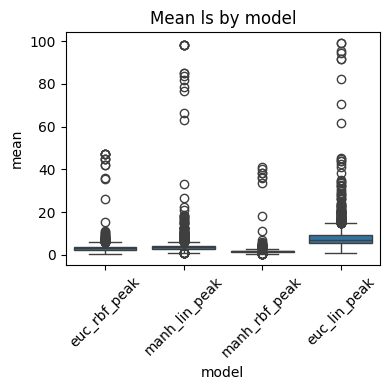

In [7]:
#plot ls
ls_pre = df[df['Unnamed: 0'] == "ls_subject_transformed"]
ls_pre = ls_pre.drop_duplicates(subset=["ID", "model", "run"], keep="first").reset_index(drop=True)
ls_pre["r_hat"] = pd.to_numeric(ls_pre["r_hat"], errors='coerce')

ls_pre = ls_pre[ls_pre["model"].isin(["euc_rbf_peak", "euc_lin_peak", "manh_rbf_peak", "manh_lin_peak"])]


#check that we have all fits
uniquerows = len(ls_pre)
print(uniquerows)
print(ls_pre["ID"].nunique())
print(ls_pre["run"].nunique())
print(ls_pre["model"].nunique())


#plot ls
ls_pre['run'] = ls_pre['run'].astype(int)
ls_pre["mean"] = pd.to_numeric(ls_pre["mean"], errors="coerce")

plt.figure(figsize=(4,4))
sns.boxplot(x='model', y='mean', data=ls_pre)
plt.xticks(rotation=45)
plt.title("Mean ls by model")
plt.tight_layout()
plt.show()

7411
237
9
4


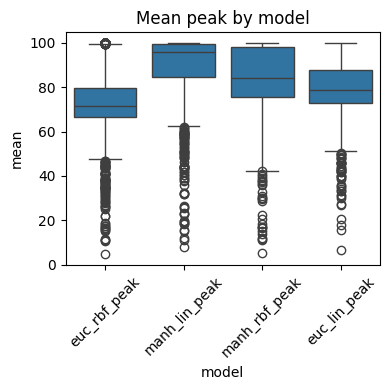

In [8]:
#plot mean
peak_rows = df[df['Unnamed: 0'] == "peak_subject_transformed"]
peak_rows = peak_rows.drop_duplicates(subset=["ID", "model", "run"], keep="first").reset_index(drop=True)
peak_rows["r_hat"] = pd.to_numeric(peak_rows["r_hat"], errors='coerce')

peak_rows = peak_rows[peak_rows["model"].isin(["euc_rbf_peak", "euc_lin_peak", "manh_rbf_peak", "manh_lin_peak"])]


#check that we have all fits
uniquerows = len(peak_rows)
print(uniquerows)
print(peak_rows["ID"].nunique())
print(peak_rows["run"].nunique())
print(peak_rows["model"].nunique())


peak_rows['run'] = peak_rows['run'].astype(int)
peak_rows["mean"] = pd.to_numeric(peak_rows["mean"], errors="coerce")

plt.figure(figsize=(4,4))
sns.boxplot(x='model', y='mean', data=peak_rows)
plt.xticks(rotation=45)
plt.title("Mean peak by model")
plt.tight_layout()
plt.show()

In [9]:
#extract info 
df_pre = pd.concat([peak_rows, ls_pre], ignore_index=True)


### POST ratings

In [10]:
parent_dir = os.path.abspath(os.path.join(os.getcwd(), "../../.."))
directory = os.path.join(parent_dir, "fitted/gp_fitted/ratingPOST")


csv_files = glob.glob(os.path.join(directory, "*.csv"))
good_files = []
bad_files = []

for f in csv_files:
    try:
        df_temp = pd.read_csv(f)
        good_files.append(f)
    except pd.errors.EmptyDataError:
        bad_files.append(f)
    except Exception as e:
        print(f"Problem with {f}: {e}")
        bad_files.append(f)


if good_files:
    df2 = pd.concat((pd.read_csv(f) for f in good_files), ignore_index=True)
    print(f"\nLoaded {len(good_files)} of {len(csv_files)} files successfully.")
    print(f"Skipped {len(bad_files)} bad/empty files.")
    print(f"Total rows: {len(df2)}")
    print(f"Models: {df2['model'].unique()}")
    print(f"Unique IDs: {len(df2['ID'].unique())}")


Loaded 15430 of 15430 files successfully.
Skipped 0 bad/empty files.
Total rows: 104774
Models: ['euc_rbf_peak' 'manh_lin_peak' 'manh_rbf_peak' 'manh_lin' 'euc_rbf'
 'manh_rbf' 'euc_lin_peak' 'euc_lin']
Unique IDs: 237


In [11]:
#extract predictions for MDP here

mdpdf = df2[df2["Unnamed: 0"] == "res"].copy()
mdpdf = mdpdf[mdpdf["model"] == "euc_rbf_peak"]
mdpdf = mdpdf[["ID", "run", "mean"]].rename(columns={"mean": "rewards", "ID": "participant"})

# Clean up
def clean_mu(val, shape=(11,11)):
    if isinstance(val, str):
        cleaned = re.sub(r"[\[\]\n]", " ", val)
        cleaned = re.sub(r"\s+", " ", cleaned).strip()
        arr = np.fromstring(cleaned, sep=" ")
        arr = arr.reshape(shape)
        
        rows = ["[" + " ".join(f"{x:g}" for x in row) + "]" for row in arr]
        arr_str = "[" + "\n ".join(rows) + "]"
        
        return arr_str
    return val

mdpdf["rewards"] = mdpdf["rewards"].apply(clean_mu)
print(mdpdf)

            participant  run  \
8        66250883594477    8   
68      699950980993832    5   
178     104317672833187    1   
202     908257540979670    3   
240     561210444304629    6   
...                 ...  ...   
104526  889297999217777    7   
104574  401272912789163    6   
104653  818993877228241    2   
104676  140007296537372    7   
104685  686528870175854    5   

                                                  rewards  
8       [[23.99 29.4453 34.533 38.6971 41.4331 42.3874...  
68      [[8.51789 11.3055 14.3666 17.4788 20.3591 22.7...  
178     [[3.7947 5.6481 7.69579 9.59893 10.9599 11.455...  
202     [[13.6755 17.322 19.9618 20.9283 19.9618 17.32...  
240     [[29.9153 35.8367 41.7553 47.3188 52.1545 55.9...  
...                                                   ...  
104526  [[3.5971 5.18732 6.89652 8.45266 9.55029 9.947...  
104574  [[8.60196 14.7783 22.516 30.4189 36.4375 38.69...  
104653  [[14.5966 19.5526 24.5451 28.8745 31.831 32.88...  
104676  [[12.18

6906
237
9
4


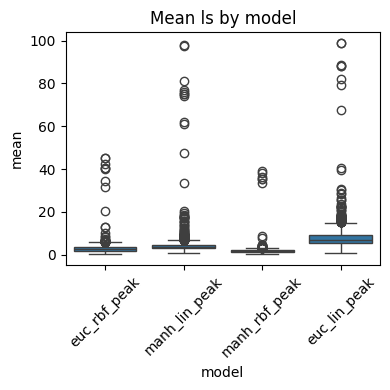

In [12]:
#plot ls
ls_post = df2[df2['Unnamed: 0'] == "ls_subject_transformed"]
ls_post = ls_post.drop_duplicates(subset=["ID", "model", "run"], keep="first").reset_index(drop=True)
ls_post["r_hat"] = pd.to_numeric(ls_post["r_hat"], errors='coerce')

ls_post = ls_post[ls_post["model"].isin(["euc_rbf_peak", "euc_lin_peak", "manh_rbf_peak", "manh_lin_peak"])]


#check that we have all fits
uniquerows = len(ls_post)
print(uniquerows)
print(ls_post["ID"].nunique())
print(ls_post["run"].nunique())
print(ls_post["model"].nunique())


#plot ls
ls_post['run'] = ls_post['run'].astype(int)
ls_post["mean"] = pd.to_numeric(ls_post["mean"], errors="coerce")

plt.figure(figsize=(4,4))
sns.boxplot(x='model', y='mean', data=ls_post)
plt.xticks(rotation=45)
plt.title("Mean ls by model")
plt.tight_layout()
plt.show()

6906
237
9
4


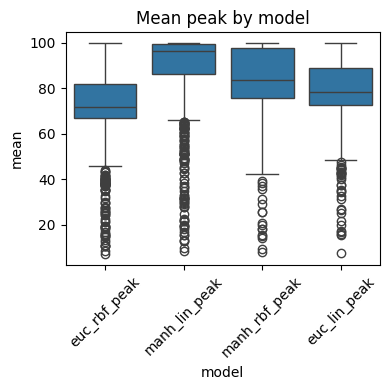

In [13]:
#plot mean
peak_rows = df2[df2['Unnamed: 0'] == "peak_subject_transformed"]
peak_rows = peak_rows.drop_duplicates(subset=["ID", "model", "run"], keep="first").reset_index(drop=True)
peak_rows["r_hat"] = pd.to_numeric(peak_rows["r_hat"], errors='coerce')

peak_rows = peak_rows[peak_rows["model"].isin(["euc_rbf_peak", "euc_lin_peak", "manh_rbf_peak", "manh_lin_peak"])]


#check that we have all fits
uniquerows = len(peak_rows)
print(uniquerows)
print(peak_rows["ID"].nunique())
print(peak_rows["run"].nunique())
print(peak_rows["model"].nunique())


peak_rows['run'] = peak_rows['run'].astype(int)
peak_rows["mean"] = pd.to_numeric(peak_rows["mean"], errors="coerce")


plt.figure(figsize=(4,4))
sns.boxplot(x='model', y='mean', data=peak_rows)
plt.xticks(rotation=45)
plt.title("Mean peak by model")
plt.tight_layout()
plt.show()

In [ ]:
df_post = pd.concat([peak_rows, ls_post], ignore_index=True)
df_combined = pd.concat([df_pre, df_post], ignore_index=True)

#df_combined.to_csv("../../../output/GP_parameters/params&fit.csv", index=False)